# Week 4 Seminar · NumPy: data as numbers

In the lecture we saw that a computer only ever sees **numbers**:
a table becomes a **matrix**, one row becomes a **vector**, and a photo becomes a **grid of numbers**.

Today you do all of that yourself, in code, with **NumPy**, the library almost every AI tool is built on.

### How this notebook works

| Part | Topic |
|---|---|
| 1 | From lists to arrays |
| 2 | The whole table: a matrix |
| 3 | Dot product = weighted sum (+ challenge) |
| 4 | Distance = similarity |
| 5 | Images are arrays |
| 6 | Shape bugs |
| 7 | Check the AI’s code |

When you finish, the notebook should run from top to bottom with **Runtime → Run all**.

## 0 · Setup
Run this cell first. `np` is the short name everyone uses for NumPy. Officially it is known as **Alias**. You can call it whatever, but the practice is to use np, an abbreviation any programmer would understand. 

In [1]:
import numpy as np
# Matplotlib is for plotting, an art in itself
import matplotlib.pyplot as plt

In [2]:
# same random numbers every time = reproducible results
np.random.seed(42)

def check(condition, message="Correct!"):
    """Print a the output if condition is True, otherwise a hint."""
    if condition:
        print(message)
    else:
        print("Not yet. Look at your answer again.")


print("NumPy version:", np.__version__)

NumPy version: 2.5.4


## 1 · From lists to arrays

Last week you stored data in **lists**. Lists are great for storing things, but they are bad at maths.

**Predict:** what will `sizes_list * 2` print? Write your guess in the comment, then run.

In [3]:
# sizes of 5 flats in m²
sizes_list = [85, 62, 110, 48, 95]

print(sizes_list * 2)

[85, 62, 110, 48, 95, 85, 62, 110, 48, 95]


Surprise: a list doesn’t double the numbers, it **repeats the list**. In order to double the elements you need to either run a for-loop or a list comprehension. Now the same thing with a NumPy **array**

In [4]:
# last week's predict_price, for all 5 flats at once!
sizes = np.array([85, 62, 110, 48, 95])

print(sizes * 2)
print(sizes * 1450)

[170 124 220  96 190]
[123250  89900 159500  69600 137750]


An array does the maths **element by element**, with no loop. `sizes * 1450` is your Week 3 model, applied to every flat in one line.

Every array knows three things about itself:

In [5]:
# how many numbers, in each direction
print("shape:", sizes.shape)
# how many directions (1 = a vector)
print("ndim: ", sizes.ndim)
# what kind of numbers (int = whole numbers)
print("dtype:", sizes.dtype)

shape: (5,)
ndim:  1
dtype: int64


In [8]:
# # Fill in: the same 5 flats have **3, 2, 4, 1, 3** rooms. Make an array called `rooms`.
rooms = np.array([3, 2, 4, 1, 3])

# print(rooms)
# print(rooms.shape)
# check(rooms.shape == (5,) and rooms.sum() == 13)

Two arrays of the same length can be combined element by element (Element-wise)

In [9]:
m2_per_room = sizes / rooms
print(m2_per_room.round(1))

[28.3 31.  27.5 48.  31.7]


In [10]:
# here are the prices. Compute the **price per m²** of each flat.
prices = np.array([142000, 74000, 138000, 69000, 121000])

# price_per_m2 = 

# print(price_per_m2.round(0))
# print("Average €/m²:", price_per_m2.mean().round(0))
# check(np.allclose(price_per_m2, prices / sizes))

Useful array methods: `.sum()`, `.mean()`, `.min()`, `.max()`, `.round(1)`. You will use them all the time.

## 2 · The whole table: a matrix

Now all **20 Tirana flats**, one array per column of the table (made-up data, like last week).

In [11]:
size_m2 = np.array([85, 62, 110, 48, 95, 70, 55, 120, 78, 66,
                    90, 102, 45, 83, 130, 60, 75, 98, 52, 115])
rooms = np.array([3, 2, 4, 1, 3, 2, 1, 4, 2, 2,
                  3, 3, 1, 3, 4, 2, 2, 3, 1, 4])
area = np.array(["Blloku", "Kombinat", "Don Bosko", "Blloku", "Kombinat",
                 "Blloku", "Kombinat", "Blloku", "Don Bosko", "Kombinat",
                 "Don Bosko", "Blloku", "Don Bosko", "Kombinat", "Don Bosko",
                 "Blloku", "Kombinat", "Don Bosko", "Blloku", "Kombinat"])
price_eur = np.array([142000, 74000, 138000, 69000, 121000, 112000, 66000, 195000, 101000, 81000,
                      118000, 168000, 58000, 99000, 165000, 98000, 88000, 129000, 84000, 135000])

print(len(size_m2), "flats")

20 flats


Stack the two number columns side by side to get the **feature matrix X**. The prices are the **label y**.

In [12]:
# features: size and rooms
X = np.column_stack([size_m2, rooms])
# label: what we want to predict
y = price_eur

print("X.shape:", X.shape)
print("y.shape:", y.shape)
print(X[:5])   # the first 5 rows

X.shape: (20, 2)
y.shape: (20,)
[[ 85   3]
 [ 62   2]
 [110   4]
 [ 48   1]
 [ 95   3]]


### Selecting parts of a matrix

| Code | Means | Result |
|---|---|---|
| `X[0]` | row 0 (the first flat) | a vector |
| `X[:, 0]` | all rows, column 0 (all sizes) | a vector |
| `X[2, 1]` | row 2, column 1 | one number |
| `X[:3]` | the first 3 rows | a smaller matrix |
| `X[-1]` | the last row | a vector |

Python counts from **0**, so the 5th flat is `X[4]`. The `:` means “all of them”.

In [15]:
print("First flat: ", X[0])
print("-" * 20)
print("All sizes: ", X[:, 0])
print("-" * 20)
print("Rooms of flat 3: ", X[2, 1])

First flat:  [85  3]
--------------------
All sizes:  [ 85  62 110  48  95  70  55 120  78  66  90 102  45  83 130  60  75  98
  52 115]
--------------------
Rooms of flat 3:  4


In [19]:
# Some more practice
# the 5th flat
fifth_flat = X[4,:]
# the whole rooms column
all_rooms  = X[:,1]
# the last 3 flats
last_three = X[-3:,]

print(fifth_flat, all_rooms, last_three, sep="\n")
check(list(fifth_flat) == [95, 3], "fifth_flat is right")
check(all_rooms.shape == (20,) and all_rooms.sum() == 50, "all_rooms is right")
check(last_three.shape == (3, 2) and last_three[0, 0] == 98, "last_three is right")

[95  3]
[3 2 4 1 3 2 1 4 2 2 3 3 1 3 4 2 2 3 1 4]
[[ 98   3]
 [ 52   1]
 [115   4]]
fifth_flat is right
all_rooms is right
last_three is right


### Filtering with a condition
A comparison gives an array of `True`/`False`, and you can use it to keep only some rows. (You will do much more of this with Pandas next week.)

In [20]:
is_big = X[:, 0] > 100
print(is_big)
# Select only the rows that are true based on 1st column (index 0)
print("Big flats:\n", X[is_big])

# True = 1, False = 0
print("How many:", is_big.sum())

[False False  True False False False False  True False False False  True
 False False  True False False False False  True]
Big flats:
 [[110   4]
 [120   4]
 [102   3]
 [130   4]
 [115   4]]
How many: 5


In [23]:
# what is the average price of flats in Blloku?
# area is a vector, so from that we select only "Blloku" values, so we get a True/False Vector
in_blloku =  area == "Blloku"
print(in_blloku)
print("-" * 20)

avg_blloku = y[in_blloku].mean()
print("Average Blloku price:", avg_blloku.round(0))
check(round(avg_blloku) == 124000)

[ True False False  True False  True False  True False False False  True
 False False False  True False False  True False]
--------------------
Average Blloku price: 124000.0
Correct!


### One-hot encoding

The model can’t multiply the word “Blloku”. So we make one **yes/no column per area**: 1 if the flat is there, 0 if not.

**Fill in** the `kombinat` and `don_bosko` lines, following the pattern.

In [25]:
# First let me see what values i have
np.unique(area)

array(['Blloku', 'Don Bosko', 'Kombinat'], dtype='<U9')

In [31]:
blloku = (area == "Blloku").astype(int)
print(area)
print("-"* 40)
# If Blloku = 1, Otherwise = 0
print(blloku)

['Blloku' 'Kombinat' 'Don Bosko' 'Blloku' 'Kombinat' 'Blloku' 'Kombinat'
 'Blloku' 'Don Bosko' 'Kombinat' 'Don Bosko' 'Blloku' 'Don Bosko'
 'Kombinat' 'Don Bosko' 'Blloku' 'Kombinat' 'Don Bosko' 'Blloku'
 'Kombinat']
----------------------------------------
[1 0 0 1 0 1 0 1 0 0 0 1 0 0 0 1 0 0 1 0]


In [32]:
# COnvert the others in the same way
kombinat  = (area == "Kombinat").astype(int)
don_bosko = (area == "Don Bosko").astype(int)

X5 = np.column_stack([size_m2, rooms, blloku, kombinat, don_bosko])

print("X5.shape:", X5.shape)
print("First flat as a vector:", X5[0])
check(X5.shape == (20, 5) and (X5[:, 2:].sum(axis=1) == 1).all(), "Every flat is in exactly one area")

X5.shape: (20, 5)
First flat as a vector: [85  3  1  0  0]
Every flat is in exactly one area


In [34]:
# Let's see the first 5 rows
X5[:5]

array([[ 85,   3,   1,   0,   0],
       [ 62,   2,   0,   1,   0],
       [110,   4,   0,   0,   1],
       [ 48,   1,   1,   0,   0],
       [ 95,   3,   0,   1,   0]])

## 3 · Dot product = weighted sum

A **weight** says how much each feature is worth. Here: **1,400 € per m²** and **5,000 € per room**.

**Predict:** what price do these weights give the first flat (85 m², 3 rooms)? Work it out on paper first.

Dot Product is the most important concept you need to make sure you understand. Take a piece of paper and a pen and sit down and do some multiplications my hand until the mechanisc settle. It will help you a lot in the future. All AI is dot product in disguise.

In [35]:
# Remember X was a 2D matrix of size and rooms
print(X.shape)
print("-" * 20)
X[:5]

(20, 2)
--------------------


array([[ 85,   3],
       [ 62,   2],
       [110,   4],
       [ 48,   1],
       [ 95,   3]])

In [41]:
# € per m², € per room
w = np.array([1400, 5000])
print(w)
print()
print(w[0])
print(w[1])
# first flat: [85, 3]
x = X[0]
print("-" * 20)
print(x)
print()
print(x[0])
print(x[1])

[1400 5000]

1400
5000
--------------------
[85  3]

85
3


In [42]:
by_hand = w[0] * x[0] + w[1] * x[1]
print("By hand:", by_hand)
print("np.dot(w,x):", np.dot(w, x))
print("w @ x:", w @ x)

By hand: 134000
np.dot(w,x): 134000
w @ x: 134000


Three ways, same answer. **Multiply position by position, then add up**: that is the dot product. From now on we use `@`.

In [45]:
# price the 3rd flat with the same weights
third_price = w @ X[2,]
print(third_price)
check(third_price == 174000)

174000
Correct!


### Every flat at once
`X @ w` does one dot product **per row**.

What is the shape of `predictions`?

In [46]:
predictions = X @ w

print("shape:", predictions.shape)

for i in range(5):
    print(f"Flat {i+1}: predicted {predictions[i]:>8,} €   real {y[i]:>8,} €")

shape: (20,)
Flat 1: predicted  134,000 €   real  142,000 €
Flat 2: predicted   96,800 €   real   74,000 €
Flat 3: predicted  174,000 €   real  138,000 €
Flat 4: predicted   72,200 €   real   69,000 €
Flat 5: predicted  148,000 €   real  121,000 €


How good is the model? As in Week 3, take the **average error** (ignoring the sign):

In [47]:
errors = predictions - y
average_error = np.abs(errors).mean()
print(f"Average error: {average_error:,.0f} €")

Average error: 19,120 €


### Challenge: beat the weights

**Part A.** Change the two weights to get a **lower average error** than above. Write your best score on the board.

In [48]:
w_mine = np.array([1000, 2000])   # € per m², € per room

my_error = np.abs(X @ w_mine - y).mean()
print(f"My average error: {my_error:,.0f} €")

My average error: 25,100 €


**Part B.** Now use **X5**, which knows the area. You need **5 weights**: per m², per room, and an extra amount for each area.
Think like an estate agent: which area should get the biggest extra amount?

In [49]:
#                   per m²  per room  Blloku  Kombinat  Don Bosko
w5_mine = np.array([1200, 3000, 10, 3, 7])

my_error5 = np.abs(X5 @ w5_mine - y).mean()
print(f"My average error with area: {my_error5:,.0f} €")

My average error with area: 11,927 €


### Let Computer find the best weights

**Let the computer do it.** NumPy can find the best weights for us. Treat it as a black box today: how it works is week 8 (*gradient descent*) and Foundations of ML.

In [50]:
# black box for now: "find the best weights"
w5_best, *_ = np.linalg.lstsq(X5, y, rcond=None)

print("Best weights:", w5_best.round(0))
best_error = np.abs(X5 @ w5_best - y).mean()
print(f"Computer's average error: {best_error:,.0f} €")

Best weights: [  1438.   -527.  14908. -17036. -12375.]
Computer's average error: 5,191 €


### Things to think about

- Look at the 3 area weights. What do they tell a buyer about Tirana?
- Why did adding the area help so much? (Remember Week 3: the missing feature.)
- The computer gives **rooms a negative weight**. Does an extra room really lower the price? Hint: bigger flats have more rooms, so the size weight already covers most of it. Weights are not always easy to read on their own.

## 4 · Distance = similarity

The three flats from the lecture. `np.linalg.norm(a - b)` is the straight-line distance between two vectors.

**Predict:** which flat is closest to A?

In [52]:
A = np.array([85, 3])
B = np.array([90, 1])
C = np.array([60, 3])

print("A to B:", np.linalg.norm(A - B).round(1))
print("A to C:", np.linalg.norm(A - C).round(1))
print("A to C:", np.linalg.norm(B - C).round(1))

A to B: 5.4
A to C: 25.0
A to C: 30.1


### Normalization

Remeber from statistics: The Normal Distribution (Gaussian)

B “wins” only because m² are bigger numbers than rooms. Fix: divide each column by its **typical spread** (the standard deviation), so both features count fairly.

In [54]:
# axis=0 means "down each column"
spread = X.std(axis=0)
print("Typical spread (size, rooms):", spread.round(1))

A_s, B_s, C_s = A / spread, B / spread, C / spread
print("A to B (scaled):", np.linalg.norm(A_s - B_s).round(2))
print("A to C (scaled):", np.linalg.norm(A_s - C_s).round(2))
print("A to C (scaled):", np.linalg.norm(B_s - C_s).round(2))

Typical spread (size, rooms): [24.5  1. ]
A to B (scaled): 1.96
A to C (scaled): 1.02
A to C (scaled): 2.3


Now C is the closest, which matches common sense: it has the same number of rooms.

### Similar Listings

**Fill in:** a client wants a flat like **80 m², 2 rooms**. Which flat in our data is most similar? (This is how “similar listings” works on property websites.)

In [55]:
new_flat = np.array([80, 2])

X_scaled = X / spread
new_scaled = new_flat / spread
# one distance per flat
distances = np.linalg.norm(X_scaled - new_scaled, axis=1)
distances

array([0.99697948, 0.73414523, 2.30361901, 1.62965943, 1.1518095 ,
       0.40785846, 1.41140329, 2.54383573, 0.08157169, 0.57100185,
       1.05770009, 1.32571031, 1.72920513, 0.98354071, 2.82280657,
       0.81571692, 0.20392923, 1.22120849, 1.50218287, 2.41811771])

In [57]:
# position of the smallest
closest = np.argmin(distances)
print(closest)
print()
print("Most similar flat: number", closest + 1, "→", X[closest], area[closest], f"{y[closest]:,} €")
check(closest == 8)

8

Most similar flat: number 9 → [78  2] Don Bosko 101,000 €
Correct!


## 5 · Images are arrays

### 5a · The “7” from the lecture

Each number is one pixel: **0 = black, 255 = white**.

shape: (8, 8)


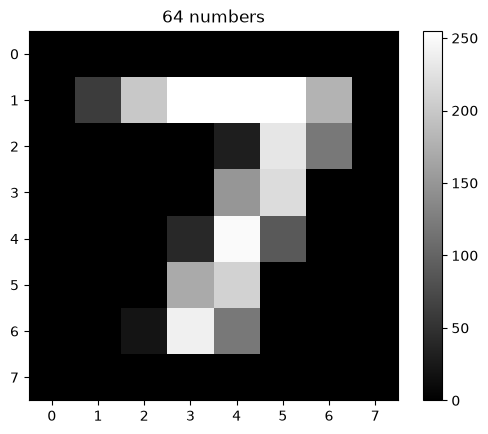

In [58]:
seven = np.array([
    [0,  0,   0,   0,   0,   0,   0, 0],
    [0, 60, 200, 255, 255, 255, 180, 0],
    [0,  0,   0,   0,  30, 230, 120, 0],
    [0,  0,   0,   0, 150, 220,   0, 0],
    [0,  0,   0,  40, 250,  90,   0, 0],
    [0,  0,   0, 170, 210,   0,   0, 0],
    [0,  0,  20, 240, 120,   0,   0, 0],
    [0,  0,   0,   0,   0,   0,   0, 0],
])

print("shape:", seven.shape)
plt.imshow(seven, cmap="gray", vmin=0, vmax=255)
plt.colorbar()
plt.title("64 numbers")
plt.show()

### Practice

Many Europeans (me included) write a 7 with a **crossbar**. Set row 4, columns 2 to 5 to white (255).
Hint: `img[row, start:stop]`, where `stop` is *not* included.

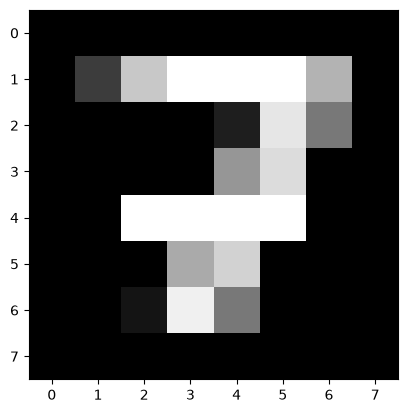

Correct!


In [59]:
# copy, so the original stays unchanged
seven_euro = seven.copy()
seven_euro[4, 2:6] = 255

plt.imshow(seven_euro, cmap="gray", vmin=0, vmax=255)
plt.show()
check((seven_euro[4, 2:6] == 255).all() and seven_euro[4, 1] == 0)

### Shift the Colors

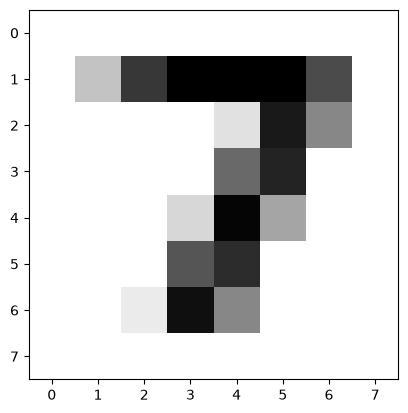

In [60]:
plt.imshow(255 - seven, cmap="gray", vmin=0, vmax=255)
plt.show()

### 5b · Real handwritten digits
scikit-learn comes with 1,797 small scanned digits (8 × 8 pixels). Note: these use values **0–16** instead of 0–255.

In [ ]:
from sklearn.datasets import load_digits

digits = load_digits()
print("images:", digits.images.shape)   # (how many, height, width)
print("labels:", digits.target[:10])

fig, axes = plt.subplots(1, 10, figsize=(12, 2))
for i, ax in enumerate(axes):
    ax.imshow(digits.images[i], cmap="gray")
    ax.set_title(digits.target[i])
    ax.axis("off")
plt.show()

🔮 **Predict:** a model needs one **row** per example. What shape will `digits.data` have?

In [ ]:
# My guess: ...
print("data:", digits.data.shape)
print("Is row 0 just image 0 flattened?", np.array_equal(digits.images[0].flatten(), digits.data[0]))

That’s **flattening**: 8 × 8 = 64 numbers in one row. It’s exactly what the SVM in Week 2 learned from (with 28 × 28 = 784).

✏️ **Fill in:** turn row 5 back into an image.

In [ ]:
image_5 = digits.data[5].reshape(____)

plt.imshow(image_5, cmap="gray")
plt.title(f"Label: {digits.target[5]}")
plt.show()
check(image_5.shape == (8, 8))

Because images are just numbers, we can do maths on them. Here is the **average of all the 7s**:

In [ ]:
all_sevens = digits.images[digits.target == 7]
print("How many 7s:", all_sevens.shape)

plt.imshow(all_sevens.mean(axis=0), cmap="gray")
plt.title("The average 7")
plt.show()

✏️ **Fill in:** make the average of a digit of your choice.

In [ ]:
my_digit = ____
plt.imshow(digits.images[digits.target == my_digit].mean(axis=0), cmap="gray")
plt.title(f"The average {my_digit}")
plt.show()

### 5c · Colour images: three numbers per pixel
A colour image has shape **(height, width, 3)**: red, green and blue, each 0–255.

In [ ]:
img = np.zeros((4, 6, 3), dtype=np.uint8)   # 4 rows, 6 columns, 3 colours
img[:, :] = [224, 122, 47]                  # every pixel orange (the colour from the slides)
img[1:3, 2:4] = [47, 111, 176]              # a blue square in the middle

print("shape:", img.shape, "→", img.size, "numbers")
plt.imshow(img)
plt.show()

✏️ **Fill in:** a very simple Albanian flag: a **red** background `[228, 30, 36]` with a **black** square `[0, 0, 0]` in the middle.

In [ ]:
flag = np.zeros((10, 14, 3), dtype=np.uint8)
flag[:, :] = ____
flag[3:7, 5:9] = ____

plt.imshow(flag)
plt.axis("off")
plt.show()
check(list(flag[0, 0]) == [228, 30, 36] and flag[5, 7].sum() == 0)

🔮 A phone photo is 3000 × 4000 pixels. How many numbers is that in colour? Compute it:

In [ ]:
numbers_in_photo = ____
print(f"{numbers_in_photo:,} numbers")
check(numbers_in_photo == 36_000_000)

## 6 · Shape bugs  *(10 min)*

Most errors in data code are **shape errors**. Each 💥 cell below crashes **on purpose**.

For each one:
1. Run it and read the **last line** of the error first.
2. Print the shapes involved.
3. Fix it in the ✏️ cell underneath.

💥 **Bug 1**: someone added a weight for a feature that doesn’t exist.

In [ ]:
w3 = np.array([1400, 5000, 20000])
X @ w3

In [ ]:
# ✏️ Fix: X has 2 columns, so w needs 2 weights
w_fixed = np.array(____)
print((X @ w_fixed).shape)
check((X @ w_fixed).shape == (20,))

💥 **Bug 2**: the right weights, the wrong matrix.

In [ ]:
X5 @ w

In [ ]:
# ✏️ Fix: w has 2 weights. Which matrix has 2 columns?
fixed_predictions = ____ @ w
check(fixed_predictions.shape == (20,))

💥 **Bug 3**: a column lost one value.

In [ ]:
rooms_short = rooms[:-1]      # oops: the last flat is missing
np.column_stack([size_m2, rooms_short])

In [ ]:
# ✏️ Fix: print the two lengths, then stack two columns of the same length
print(len(size_m2), len(rooms_short))
X_fixed = np.column_stack([size_m2, ____])
check(X_fixed.shape == (20, 2))

💥 **Bug 4**: trying to show a flattened image.

In [ ]:
plt.imshow(digits.data[0], cmap="gray")

In [ ]:
# ✏️ Fix: an image needs 2 dimensions
plt.imshow(digits.data[0].reshape(____), cmap="gray")
plt.show()

## 7 · Check the AI’s code  *(5 min)*

We asked an AI assistant: *“Write a function that predicts the price of every flat in X using weights w.”* It wrote this:

In [ ]:
def predict_all(X, w):
    predictions = []
    for i in range(len(w)):
        predictions.append(X[i] @ w)
    return np.array(predictions)


result = predict_all(X, w)
print(result)

No error, so it works… right? 🔮 Before reading on: **how many predictions should there be?** Check the shape:

In [ ]:
print("Shape we got:     ", result.shape)
print("Shape we expected:", (X.shape[0],))

The bug: `range(len(w))` loops over the **2 weights** instead of the **20 flats**, so only 2 flats get a price. There was **no error message**; only checking the shape caught it.

✏️ **Fill in:** rewrite the function in one line, using what you learned today.

In [ ]:
def predict_all(X, w):
    return ____


check(predict_all(X, w).shape == (20,), "20 predictions, one per flat")

## Wrap-up

| Idea | NumPy |
|---|---|
| A column or a row is a **vector** | `np.array([...])`, `.shape == (n,)` |
| A table is a **matrix** | `np.column_stack([...])`, `.shape == (rows, columns)` |
| Select rows / columns | `X[0]`, `X[:, 1]`, `X[X[:, 0] > 100]` |
| Categories to numbers | `(area == "Blloku").astype(int)` |
| Weighted sum | `w @ x` |
| Every prediction at once | `X @ w` |
| Similarity | `np.linalg.norm(a - b)` |
| Image | `(height, width)` or `(height, width, 3)`; `.flatten()`, `.reshape()` |

**Habits to keep:** print `.shape` after every step · read the *last* line of an error first · check AI code by running it *and* checking its shapes.

**Next week:** Pandas. Real tables with column names, loading files, filtering, plus probability by simulation.

✅ Before you leave: **Runtime → Restart and run all**, and check the whole notebook runs without surprises (the 💥 cells will still show their errors; that’s expected).